# B3 v7 — Refined Grid Search

v7 refinements vs v6:
- Dropped 30Δ and 50Δ/straddle (consistently poor)
- Dropped 0.75 profit target (little differentiation)
- Dropped defensive_leg_roll (ΔSharpe ±0.03, negligible)
- Fixed bugs: vol-cache key, force-close double-append, entry_db_pct scale


## 1. Imports

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(ROOT / 'src'))
from grid_search import run_grid, enumerate_grid, GRID_DIMS, DTE_MIN_BY_DTE_MAX

OUT_DIR      = ROOT / 'data' / 'B3'
RESULTS_PATH = OUT_DIR / 'v7_grid_search_results.parquet'
DB_PATH      = ROOT / 'data' / 'B3' / 'b3_options_rb3.db'

## 2. Grid Definition (v7)

In [2]:
GRID = {
    "target_delta": [0.12, 0.16, 0.20, 0.25],  # dropped 30Δ, 50Δ
    "dte_max": [21, 30, 45, 60],
    "profit_target_pct": [0.25, 0.50],  # dropped 0.75
    "manage_at_dte": [5, 7, 14, 21],
    "vix_filter": ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90"],
    "defensive_leg_roll": [False],  # dropped True
    "stop_loss_pct": [2.0, 3.0],
    "execution_mode": ["bid_ask", "mid", "mid_plus_1tick"],
    "portfolio_mode": ["laddering"],
}
# 4×4×2×4×4×1×2×3×1 = 3,072 raw; ~2,688 valid after validity filter
combos = enumerate_grid(GRID)
print(f"Grid: {len(combos)} valid combos × 2 periods = {len(combos) * 2} backtests")

Grid: 3072 raw combos, 2688 after validity filter (384 dropped)
Grid: 2688 valid combos × 2 periods = 5376 backtests


## 3. Run Configuration

In [3]:
RUNS = [
    ("train", "bova11", "2018-01-02", "2022-12-30"),
    ("holdout", "bova11", "2023-01-02", "2025-11-30"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2018-01-02', '2022-12-30')
('holdout', 'bova11', '2023-01-02', '2025-11-30')


## 4. Execute Grid Search

In [4]:
from straddle.strategy import clear_vol_cache

clear_vol_cache()  # ensure no stale cache from prior runs

if RESULTS_PATH.exists():
    print(f"Loading cached results from {RESULTS_PATH}")
    results = pd.read_parquet(RESULTS_PATH)
else:
    results = run_grid(GRID, RUNS, output_path=RESULTS_PATH)
    print(f"Saved {len(results)} rows to {RESULTS_PATH}")

# Filter to valid completed runs
df = results[results["error"].isna() & (results["n_trades"] >= 30)].copy()
df["execution_mode"] = pd.Categorical(
    df["execution_mode"],
    categories=["bid_ask", "mid", "mid_plus_1tick"],
    ordered=True,
)
df["delta_label"] = df["target_delta"].apply(lambda x: f"{int(x*100)}Δ")

train = df[df["period_label"] == "train"]
holdout = df[df["period_label"] == "holdout"]
modes = ["bid_ask", "mid", "mid_plus_1tick"]

print(f"Total rows: {len(results):,} | valid: {len(df):,}")
print(f"Train rows: {len(train):,} | Holdout rows: {len(holdout):,}")
print(f"Error rate: {results['error'].notna().sum() / len(results):.1%}")

Loading cached results from /Users/oliversteiner/Documents/code/options-backtest/data/B3/v7_grid_search_results.parquet
Total rows: 5,376 | valid: 5,376
Train rows: 2,688 | Holdout rows: 2,688
Error rate: 0.0%


## Cell A — Sharpe vs Execution Mode

/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_92957/228416595.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_mode, labels=modes, notch=False, sym="")
/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_92957/228416595.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_mode, labels=modes, notch=False, sym="")


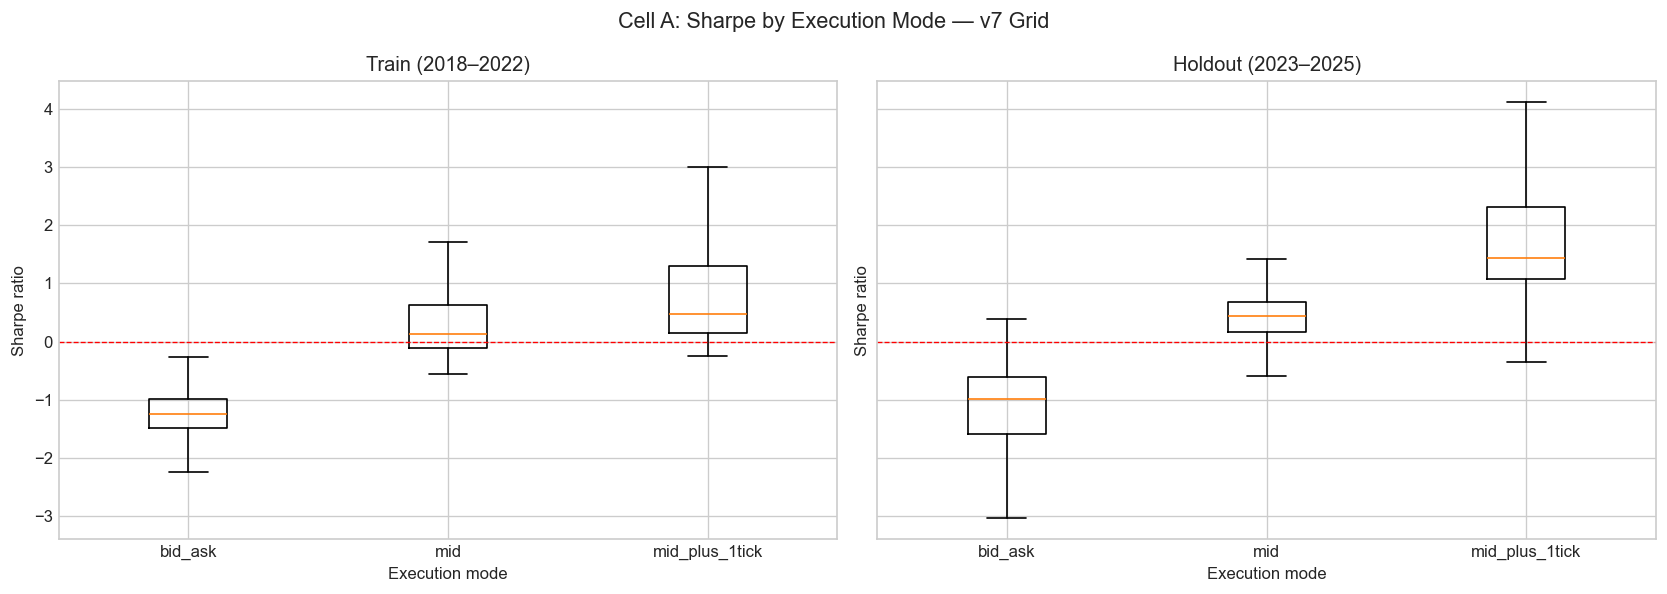

Holdout median Sharpe by execution mode:
  bid_ask              median=-0.991  pct_positive=3.6%  n=896
  mid                  median=0.437  pct_positive=86.3%  n=896
  mid_plus_1tick       median=1.445  pct_positive=98.8%  n=896


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, period_df, title in [
    (axes[0], train, "Train (2018–2022)"),
    (axes[1], holdout, "Holdout (2023–2025)"),
]:
    data_by_mode = [
        period_df[period_df["execution_mode"] == m]["sharpe"] for m in modes
    ]
    ax.boxplot(data_by_mode, labels=modes, notch=False, sym="")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("Sharpe ratio")
    ax.set_xlabel("Execution mode")
plt.suptitle("Cell A: Sharpe by Execution Mode — v7 Grid", fontsize=13)
plt.tight_layout()
plt.show()

print("Holdout median Sharpe by execution mode:")
for m in modes:
    sub = holdout[holdout["execution_mode"] == m]["sharpe"]
    pct_pos = (sub > 0).mean()
    print(
        f"  {m:<20} median={sub.median():.3f}  pct_positive={pct_pos:.1%}  n={len(sub)}"
    )

## Cell B — Break-even Execution Level

In [7]:
# For each config, determine the lowest execution mode with positive holdout Sharpe
key_cols = [c for c in GRID_DIMS if c in df.columns and c != "execution_mode"]
joined = holdout.pivot_table(index=key_cols, columns="execution_mode", values="sharpe")
joined.columns = [f"sharpe_{c}" for c in joined.columns]
joined = joined.reset_index()

categories = {
    "none_viable": (joined["sharpe_bid_ask"] > 0)
    & (joined["sharpe_mid"] <= 0)
    & (joined["sharpe_mid_plus_1tick"] <= 0),
    "bid_ask_only": (joined["sharpe_bid_ask"] > 0),
    "mid_only": (joined["sharpe_mid"] > 0) & (joined["sharpe_bid_ask"] <= 0),
    "mid_plus_1tick_only": (joined["sharpe_mid_plus_1tick"] > 0)
    & (joined["sharpe_mid"] <= 0)
    & (joined["sharpe_bid_ask"] <= 0),
}
# Reset with cleaner labels
breakeven = []
for _, row in joined.iterrows():
    if row.get("sharpe_bid_ask", -999) > 0:
        breakeven.append("bid_ask")
    elif row.get("sharpe_mid", -999) > 0:
        breakeven.append("mid")
    elif row.get("sharpe_mid_plus_1tick", -999) > 0:
        breakeven.append("mid_plus_1tick")
    else:
        breakeven.append("none")
joined["break_even"] = breakeven

print("Break-even execution level distribution (holdout):")
print(joined["break_even"].value_counts().to_string())
print(
    f"Fraction viable at mid or better: {(joined['break_even'].isin(['bid_ask','mid'])).mean():.1%}"
)
print(
    f"Fraction viable at mid_plus_1tick only: {(joined['break_even'] == 'mid_plus_1tick').mean():.1%}"
)
print(
    f"Fraction not viable at any level: {(joined['break_even'] == 'none').mean():.1%}"
)

Break-even execution level distribution (holdout):
break_even
mid               741
mid_plus_1tick    112
bid_ask            32
none               11
Fraction viable at mid or better: 86.3%
Fraction viable at mid_plus_1tick only: 12.5%
Fraction not viable at any level: 1.2%


## Cell C — Execution Mode × Target Delta Heatmap (holdout)

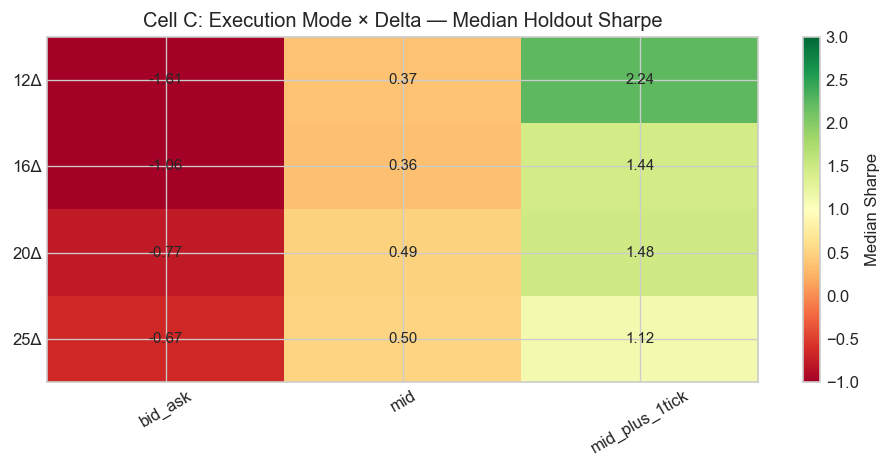

In [8]:
pivot = holdout.pivot_table(
    values="sharpe", index="delta_label", columns="execution_mode", aggfunc="median"
)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=-1, vmax=3, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=30)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Median Sharpe")
ax.set_title("Cell C: Execution Mode × Delta — Median Holdout Sharpe")
plt.tight_layout()
plt.show()

## Cell D — DTE × Target Delta Heatmap (holdout)

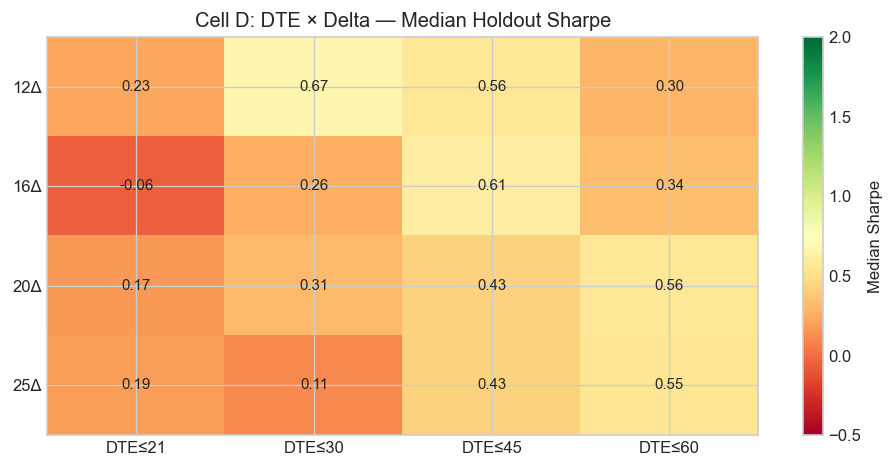

In [9]:
pivot_d = holdout.pivot_table(
    values="sharpe", index="delta_label", columns="dte_max", aggfunc="median"
)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(pivot_d.values, cmap="RdYlGn", vmin=-0.5, vmax=2, aspect="auto")
ax.set_xticks(range(len(pivot_d.columns)))
ax.set_xticklabels([f"DTE≤{d}" for d in pivot_d.columns])
ax.set_yticks(range(len(pivot_d.index)))
ax.set_yticklabels(pivot_d.index)
for i in range(len(pivot_d.index)):
    for j in range(len(pivot_d.columns)):
        ax.text(
            j, i, f"{pivot_d.values[i, j]:.2f}", ha="center", va="center", fontsize=9
        )
plt.colorbar(im, ax=ax, label="Median Sharpe")
ax.set_title("Cell D: DTE × Delta — Median Holdout Sharpe")
plt.tight_layout()
plt.show()

## Cell E — Profit Target Comparison (0.25 vs 0.50)

Holdout median Sharpe: profit_target_pct × execution_mode
execution_mode      bid_ask       mid  mid_plus_1tick
profit_target_pct                                    
0.25              -1.144738  0.283147        1.852529
0.50              -0.788387  0.531943        1.141190


/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_92957/2051822924.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_mode, labels=modes, sym="")
/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_92957/2051822924.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_mode, labels=modes, sym="")


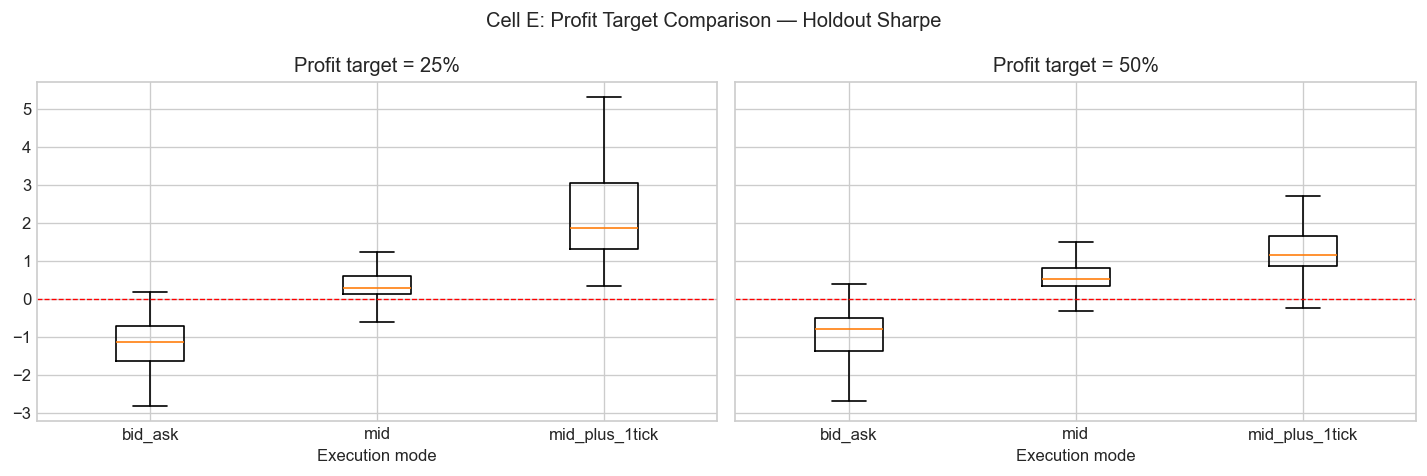

In [10]:
print("Holdout median Sharpe: profit_target_pct × execution_mode")
pt_pivot = holdout.pivot_table(
    values="sharpe",
    index="profit_target_pct",
    columns="execution_mode",
    aggfunc="median",
)
print(pt_pivot.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, pt in zip(axes, [0.25, 0.50]):
    sub = holdout[holdout["profit_target_pct"] == pt]
    data_by_mode = [sub[sub["execution_mode"] == m]["sharpe"] for m in modes]
    ax.boxplot(data_by_mode, labels=modes, sym="")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"Profit target = {pt:.0%}")
    ax.set_xlabel("Execution mode")
plt.suptitle("Cell E: Profit Target Comparison — Holdout Sharpe")
plt.tight_layout()
plt.show()

## Cell F — Vol Filter Comparison

Holdout median Sharpe by vol_filter × execution_mode:
execution_mode   bid_ask       mid  mid_plus_1tick
vix_filter                                        
OFF            -0.934920  0.409532        1.382574
rv_pct:70      -1.018105  0.464670        1.455744
rv_pct:80      -1.061847  0.465450        1.445346
rv_pct:90      -0.996109  0.432451        1.478995


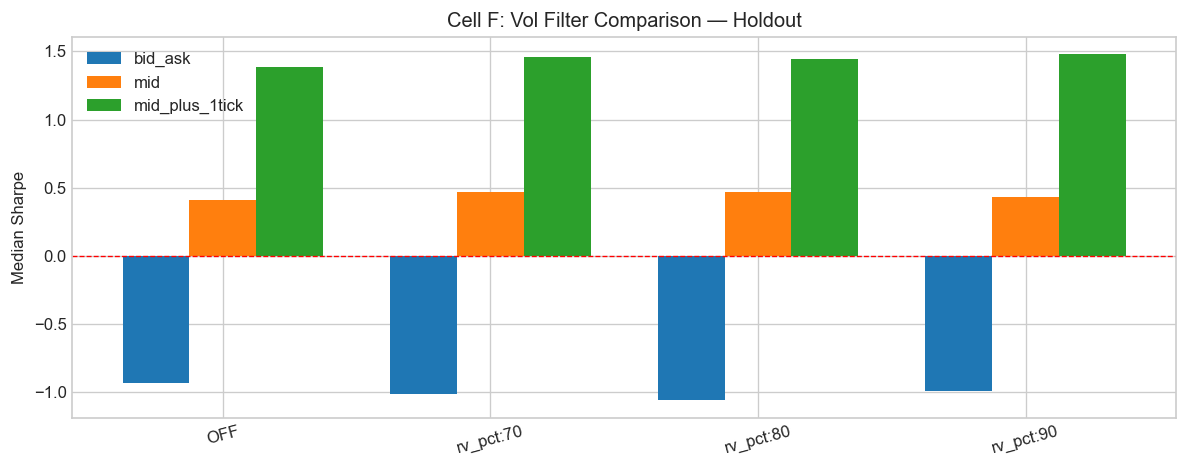

In [11]:
vf_order = ["OFF", "rv_pct:70", "rv_pct:80", "rv_pct:90"]
print("Holdout median Sharpe by vol_filter × execution_mode:")
vf_pivot = holdout.pivot_table(
    values="sharpe", index="vix_filter", columns="execution_mode", aggfunc="median"
).reindex(vf_order)
print(vf_pivot.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(vf_order))
width = 0.25
for i, m in enumerate(modes):
    vals = [
        holdout[(holdout["vix_filter"] == vf) & (holdout["execution_mode"] == m)][
            "sharpe"
        ].median()
        for vf in vf_order
    ]
    ax.bar(x + i * width, vals, width, label=m)
ax.set_xticks(x + width)
ax.set_xticklabels(vf_order, rotation=15)
ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
ax.legend()
ax.set_ylabel("Median Sharpe")
ax.set_title("Cell F: Vol Filter Comparison — Holdout")
plt.tight_layout()
plt.show()

## Cell G — Stop Loss Comparison (2.0× vs 3.0×)

Holdout median Sharpe by stop_loss_pct × execution_mode:
execution_mode   bid_ask       mid  mid_plus_1tick
stop_loss_pct                                     
2.0            -1.056273  0.465026        1.504188
3.0            -0.914778  0.415066        1.365301


/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_92957/2634137318.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_mode, labels=modes, sym="")
/var/folders/nx/dqsrmn056mg8mjbtjs9488gc0000gn/T/ipykernel_92957/2634137318.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_by_mode, labels=modes, sym="")


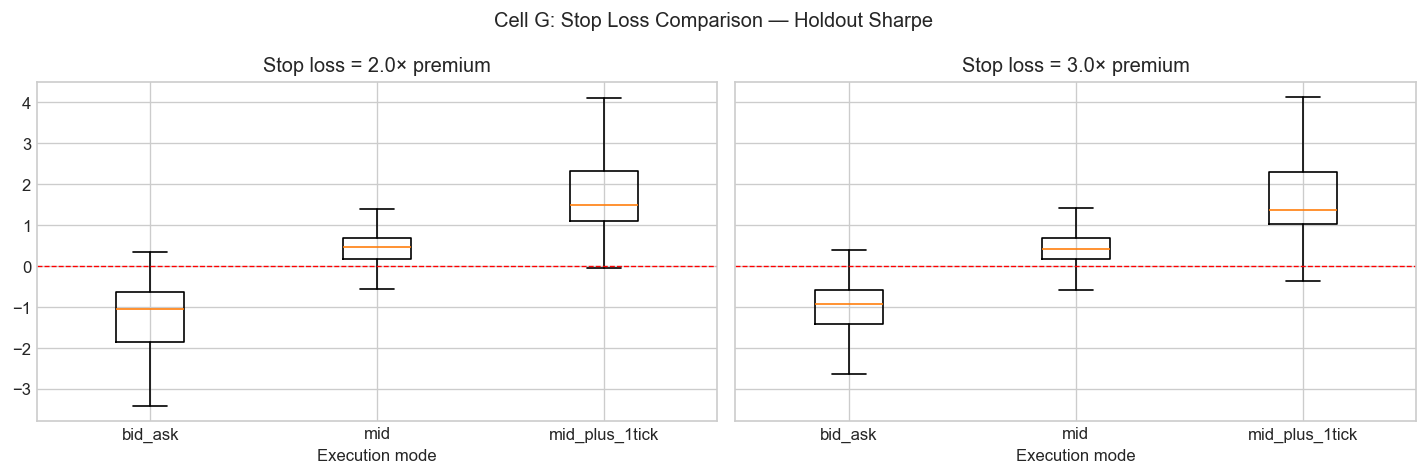

In [12]:
print("Holdout median Sharpe by stop_loss_pct × execution_mode:")
sl_pivot = holdout.pivot_table(
    values="sharpe", index="stop_loss_pct", columns="execution_mode", aggfunc="median"
)
print(sl_pivot.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, sl in zip(axes, [2.0, 3.0]):
    sub = holdout[holdout["stop_loss_pct"] == sl]
    data_by_mode = [sub[sub["execution_mode"] == m]["sharpe"] for m in modes]
    ax.boxplot(data_by_mode, labels=modes, sym="")
    ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
    ax.set_title(f"Stop loss = {sl}× premium")
    ax.set_xlabel("Execution mode")
plt.suptitle("Cell G: Stop Loss Comparison — Holdout Sharpe")
plt.tight_layout()
plt.show()

## Cell H — Train vs Holdout Scatter (Sharpe per config)

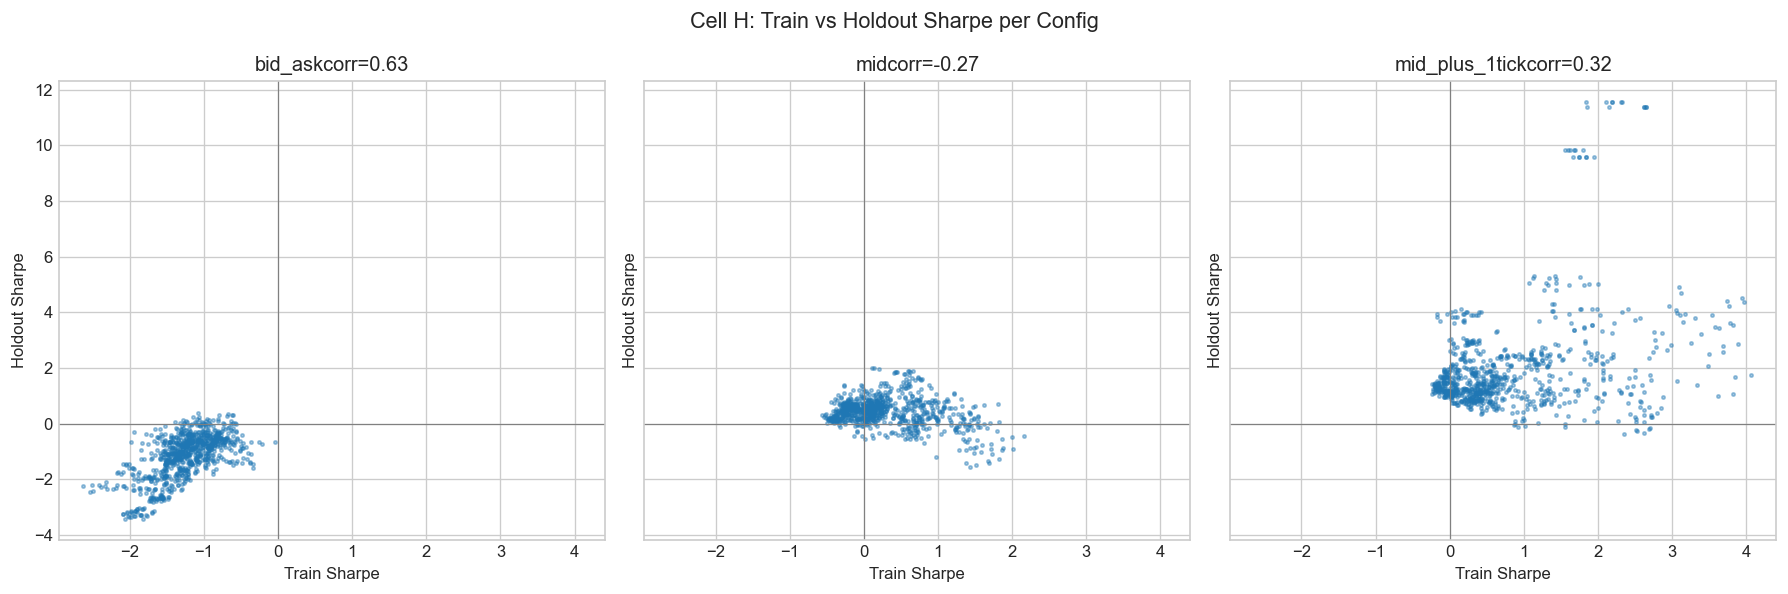

  bid_ask              0.0% positive in both train+holdout
  mid                  54.1% positive in both train+holdout
  mid_plus_1tick       84.5% positive in both train+holdout


In [14]:
# Merge train and holdout by all config dimensions
key_cols = [c for c in GRID_DIMS if c in df.columns and c != "period_label"]
t_sh = train[["sharpe"] + key_cols].rename(columns={"sharpe": "sharpe_t"})
h_sh = holdout[["sharpe"] + key_cols].rename(columns={"sharpe": "sharpe_h"})
joined2 = t_sh.merge(h_sh, on=key_cols, how="inner")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, m in zip(axes, modes):
    sub = joined2[joined2["execution_mode"] == m]
    corr = sub["sharpe_t"].corr(sub["sharpe_h"])
    ax.scatter(sub["sharpe_t"], sub["sharpe_h"], s=4, alpha=0.4)
    lim = max(abs(sub["sharpe_t"].min()), abs(sub["sharpe_h"].max())) * 1.1
    ax.axhline(0, color="grey", linewidth=0.7)
    ax.axvline(0, color="grey", linewidth=0.7)
    ax.set_title(f"{m}corr={corr:.2f}")
    ax.set_xlabel("Train Sharpe")
    ax.set_ylabel("Holdout Sharpe")
plt.suptitle("Cell H: Train vs Holdout Sharpe per Config", fontsize=13)
plt.tight_layout()
plt.show()

# Pct positive in both periods
for m in modes:
    sub = joined2[joined2["execution_mode"] == m]
    both_pos = ((sub["sharpe_t"] > 0) & (sub["sharpe_h"] > 0)).mean()
    print(f"  {m:<20} {both_pos:.1%} positive in both train+holdout")

## Cell I — DB Coverage (entry_db_pct, percentage 0–100)

In [16]:
print("=== DB Coverage ===")
for period in ["train", "holdout"]:
    print(f"{period}:")
    period_df = df[df["period_label"] == period]
    print(f'  {"mode":<22} {"entry_db_pct":>14} {"mtm_db_pct":>14}')
    for mode in modes:
        sub = period_df[period_df["execution_mode"] == mode]
        e_pct = (
            sub["entry_db_pct"].mean()
            if "entry_db_pct" in sub.columns
            else float("nan")
        )
        m_pct = (
            sub["mtm_avg_db_pct"].mean()
            if "mtm_avg_db_pct" in sub.columns
            else float("nan")
        )
        print(f"  {mode:<22} {e_pct:>14.1f}% {m_pct:>14.1f}%")

# Note: entry_db_pct and mtm_avg_db_pct are now stored as percentages (0–100),
# fixed in Phase 1 (was fraction 0–1 in v6).

=== DB Coverage ===
train:
  mode                     entry_db_pct     mtm_db_pct
  bid_ask                          48.6%           52.9%
  mid                              81.4%           59.6%
  mid_plus_1tick                   81.0%           59.7%
holdout:
  mode                     entry_db_pct     mtm_db_pct
  bid_ask                          96.5%           95.8%
  mid                              99.2%           96.0%
  mid_plus_1tick                   99.2%           95.8%


## Cell J — Best Config Details (holdout, all 3 modes)

In [18]:
param_cols = [c for c in GRID_DIMS if c in holdout.columns]
metric_cols = [
    "sharpe",
    "n_trades",
    "total_return",
    "max_drawdown",
    "win_rate",
    "calmar",
    "entry_db_pct",
]
best_per_mode = []
for m in modes:
    sub = holdout[holdout["execution_mode"] == m].sort_values("sharpe", ascending=False)
    top = sub.head(5)[param_cols + metric_cols]
    top.insert(0, "rank", range(1, 6))
    best_per_mode.append((m, top))
    print(f"=== Top 5 configs: {m} ===")
    print(top.to_string(index=False))

=== Top 5 configs: bid_ask ===
 rank  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll  stop_loss_pct execution_mode portfolio_mode   sharpe  n_trades  total_return  max_drawdown  win_rate   calmar  entry_db_pct
    1           0.2       30                0.5             14  rv_pct:70               False            3.0        bid_ask      laddering 0.388822       145      0.027740     -0.031337  0.600000 0.301436     97.241379
    2           0.2       21                0.5              7        OFF               False            2.0        bid_ask      laddering 0.341524       101      0.021054     -0.017295  0.701493 0.415441     99.009901
    3           0.2       30                0.5              7  rv_pct:70               False            2.0        bid_ask      laddering 0.323338       101      0.017484     -0.030984  0.705882 0.192792     99.009901
    4           0.2       21                0.5              7  rv_pct:80               False

## Cell K — Config Stability Rank

Sort configs by  — the conservative Pareto front.

In [20]:
key_cols_nomode = [
    c
    for c in GRID_DIMS
    if c in df.columns and c not in ("execution_mode", "period_label")
]
t_sh2 = train[["sharpe", "execution_mode"] + key_cols_nomode].rename(
    columns={"sharpe": "sharpe_t"}
)
h_sh2 = holdout[["sharpe", "execution_mode"] + key_cols_nomode].rename(
    columns={"sharpe": "sharpe_h"}
)
merge_key = ["execution_mode"] + key_cols_nomode
joined3 = t_sh2.merge(h_sh2, on=merge_key, how="inner")
joined3["min_sharpe"] = joined3[["sharpe_t", "sharpe_h"]].min(axis=1)
joined3["avg_sharpe"] = joined3[["sharpe_t", "sharpe_h"]].mean(axis=1)
stability = joined3.sort_values("min_sharpe", ascending=False)

print("Top 15 configs by min(train_sharpe, holdout_sharpe) — mid_plus_1tick:")
top15_mode = stability[stability["execution_mode"] == "mid_plus_1tick"].head(15)
display_cols = merge_key + ["sharpe_t", "sharpe_h", "min_sharpe", "avg_sharpe"]
print(top15_mode[display_cols].to_string(index=False))

print("Top 15 configs by min(train_sharpe, holdout_sharpe) — mid:")
top15_mid = stability[stability["execution_mode"] == "mid"].head(15)
print(top15_mid[display_cols].to_string(index=False))

Top 15 configs by min(train_sharpe, holdout_sharpe) — mid_plus_1tick:
execution_mode  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll  stop_loss_pct portfolio_mode  sharpe_t  sharpe_h  min_sharpe  avg_sharpe
mid_plus_1tick          0.12       21               0.25              5  rv_pct:90               False            2.0      laddering  3.976973  4.364318    3.976973    4.170646
mid_plus_1tick          0.12       21               0.25              7  rv_pct:90               False            2.0      laddering  3.952058  4.529431    3.952058    4.240745
mid_plus_1tick          0.12       21               0.25              5  rv_pct:80               False            2.0      laddering  3.765968  4.244874    3.765968    4.005421
mid_plus_1tick          0.12       21               0.25              7  rv_pct:80               False            2.0      laddering  3.738222  4.398249    3.738222    4.068236
mid_plus_1tick          0.12       21        